In [1]:
import numpy as np
import os
import re
import pandas as pd
import matplotlib.pyplot as plt
from types import SimpleNamespace
import torch
import sys 
import tifffile 
from pathlib import Path
from scripts.utils import reshape_disp, reshape_img, rmse
import torchio as tio
import ast
import napari
import re

from scripts.dataset import compute_mask
sys.path.append('/Users/josephinelahmani/Desktop/vxmorph') 
import importlib
import network
import network.models
import scripts.dataset
importlib.reload(network.models)
importlib.reload(network)
importlib.reload(scripts.dataset)
from scripts.dataset import TractionDataset
from torch.utils.data import DataLoader
from scripts.train import epoch_, update_log
from tqdm import tqdm
import importlib
import network.losses
importlib.reload(network.losses)
import network.functional
importlib.reload(network.functional)
import scripts.train
importlib.reload(scripts.train)
import yaml
import optical_flow
importlib.reload(optical_flow)
from optical_flow.algorithms import tv_l1, fista_of, hs_of


import scipy.ndimage as ndi

from quantities_computation import strain_mask, deformation, stress_mask, compute_normals_from_mask_3d, compute_traction_3d

/opt/anaconda3/envs/voxelmorph/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Data observation

In [ ]:
img = np.load(Path('/Users/josephinelahmani/helix_mount/data/synthetic/test/E_500.0_nu_0.4_nb_zones_9_im_00_seed_08_img.npy'))
viewer = napari.Viewer()

viewer.add_image(img, name='Original', scale=(1.0, 0.13, 0.13), interpolation3d='nearest')

<Image layer 'Original' at 0x1231cddf0>

## Augmentations

In [2]:
def get_transformed_img(img_path: Path, transform):
        device = 'cpu'
        
        img_raw = tifffile.imread(img_path)
        q1, q99 = np.quantile(img_raw, [0.01, 0.99])
        img = np.clip((img_raw - q1) / (q99 - q1), 0, 1)

        if img.ndim == 4:
            source_numpy = img[1]
            target_numpy = img[0]
        else:
            source_numpy = img[1, 1]
            target_numpy = img[0, 1]

        source = reshape_img(source_numpy, 32)  # (Z, H, W)
        target = reshape_img(target_numpy, 32)  # (Z, H, W)
        
        source = torch.from_numpy(source).to(device)
        target = torch.from_numpy(target).to(device)
        
        scalar_img = torch.stack([source, target], dim=0) # (2, Z, H, W)
        
        subject = tio.Subject(stack = tio.ScalarImage(tensor=scalar_img))
        
        subject = transform(subject)
        
        transformed = subject.stack.data.numpy()
        
        return np.stack([source, target], axis=0)[:,0], transformed

In [3]:
# path_img_micro = Path('/Users/josephinelahmani/helix_mount/data/micro/test/250218_WT_1p5CD100RGD_pos1_t0021_t0024.tiff') 
# path_img_synt = Path('/Users/josephinelahmani/helix_mount/data/synthetic/test/E_500.0_nu_0.4_nb_zones_9_im_01_seed_05_img.npy') 

# transforms = {
#     "RandomFlip": tio.RandomFlip(axes=("LR",), flip_probability=1.0),
#     "RandomAffine":tio.RandomAffine(scales=(0.9, 1.1), degrees=(-180, 180, 0, 0, 0, 0), translation=10),
#     "RandomNoise": tio.RandomNoise(std=(0, 0.1)),
#     "RandomGamma": tio.RandomGamma(log_gamma=(-0.8, 0.8)),
#     "RandomBlur": tio.RandomBlur(std=(0, 1)), 
#     "ComposeAll": tio.Compose(
#         [
#             tio.RandomFlip(axes=("LR",), flip_probability=1.0),
#             tio.RandomAffine(scales=(0.9, 1.1), degrees=(-180, 180, 0, 0, 0, 0), translation=8),
#             tio.RandomNoise(std=(0, 0.1)),
#             tio.RandomGamma(log_gamma=(-0.8, 0.8)),
#             tio.RandomBlur(std=(0, 1)), 
#         ]
#     )
# }

In [4]:
# viewer = napari.Viewer()

# for key, value in transforms.items(): 
#     img, transformed = get_transformed_img(path_img_synt, value)
#     viewer.add_image(transformed, name=key, scale=(1.0, 0.13, 0.13), interpolation3d='nearest')
    
# viewer.add_image(img, name='Original', scale=(1.0, 0.13, 0.13), interpolation3d='nearest')

In [5]:
# viewer_all = napari.Viewer()

# img, transformed = get_transformed_img(path_img_synt, transforms["ComposeAll"])
# viewer_all.add_image(transformed, scale=(1.0, 0.13, 0.13), interpolation3d='nearest')

## Masks

In [6]:
# mask = compute_mask(img)

# mask.shape

# plt.imshow(mask)

# Model

In [12]:
def plot_loss(folder:str, loss_part:str, init_epoch:int=0):
    if loss_part == 'total':
        name = 'loss'
    else:
        name = f'loss_{loss_part}'

    train_logs = pd.read_csv(f'{folder}/logs_train.csv').iloc[init_epoch:]
    val_logs  = pd.read_csv(f'{folder}/logs_validation.csv').iloc[init_epoch:]

    epochs = range(init_epoch + 1, len(train_logs) + init_epoch + 1)
    
    plt.plot(epochs, train_logs[name], label='train loss', color='blue')
    plt.plot(epochs, val_logs[name], label='val loss', color='red')
    plt.title(f'{name}')
    plt.xlabel('Epochs')
    plt.ylabel('Loss')
    plt.legend()
    plt.grid(True)
    plt.show()
    
    
def load_model(folder: str, model_type: str):
        os.environ['NEURITE_BACKEND'] = 'pytorch'
        os.environ['VXM_BACKEND'] = 'pytorch'

        device = 'cuda' if torch.cuda.is_available() else 'cpu'

        model_path= f'{folder}/best.pt' 

        if model_type == 'aniso':
                model = network.models.NetworkPairwiseAnisotropic(
                        ndim=3,
                        source_channels=1,
                        target_channels=1,
                        features=[16, 32, 32, 64, 64],
                ).to(device)

        else :
                model = network.models.NetworkPairwise(
                        ndim=3,
                        source_channels=1,
                        target_channels=1,
                        features=[16, 32, 32, 64],
                ).to(device)
                
        checkpoint = torch.load(model_path, map_location=device)

        model.load_state_dict(checkpoint)
        model.eval()
        
        return model

def get_img_and_results(img_path: Path, model):
        device = 'cuda' if torch.cuda.is_available() else 'cpu'
        
        ext = os.path.splitext(img_path)[1].lower()
        if ext == ".npy":
            img_raw = np.load(img_path)
        elif ext in [".tiff", ".tif"]:
            img_raw = tifffile.imread(img_path)
            
        q1, q99 = np.quantile(img_raw, [0.01, 0.99])
        img = np.clip((img_raw - q1) / (q99 - q1), 0, 1)

        if img.ndim == 4:
            source_numpy = img[1]
            target_numpy = img[0]
        else:
            source_numpy = img[1, 0]
            target_numpy = img[0, 0]

        source = reshape_img(source_numpy, 32)  # (Z, H, W)
        target = reshape_img(target_numpy, 32)  # (Z, H, W)
        
        source = torch.from_numpy(source).unsqueeze(0).to(device)
        target = torch.from_numpy(target).unsqueeze(0).to(device)
        
        subject = tio.Subject(
                source=tio.ScalarImage(tensor=source),
                target=tio.ScalarImage(tensor=target),
        )
        
        source_vxm = subject.source.data.unsqueeze(0)
        target_vxm = subject.target.data.unsqueeze(0)
        
        with torch.no_grad():  
                displacement, warped_source = model(source_vxm, target_vxm, 
                                                return_warped_source=True)

        if img.ndim == 4:
                img_padded = np.stack([reshape_img(img[0], 32), reshape_img(img[1], 32)], axis=0)
        else: 
                img_padded = np.stack([reshape_img(img[0, 0], 32), reshape_img(img[1, 0], 32)], axis=0)
        
        return img_padded, displacement, warped_source


def check_vxm(img_padded: np.ndarray, warped_image:np.ndarray, z_stack: int):
        
        diff_init = np.abs(img_padded[1, z_stack] - img_padded[0, z_stack])
        diff_warped = np.abs(warped_image[z_stack] - img_padded[0, z_stack])
        
        print('Average difference original image', np.mean(diff_init))
        print('Average difference warped image', np.mean(diff_warped))
        
        vmin_im, vmax_im = np.min(img_padded[0, z_stack]), np.max(img_padded[0, z_stack])
        
        vmin = np.min([np.min(diff_init), np.min(diff_warped)])
        vmax = np.max([np.max(diff_init), np.max(diff_warped)])
        
        fig, axes = plt.subplots(1, 5, figsize=(24, 6))
        
        im0 = axes[0].imshow(img_padded[1, z_stack], vmin=vmin_im, vmax=vmax_im)
        axes[0].set_title('Source')
        fig.colorbar(im0, ax=axes[0])
        im1 = axes[1].imshow(img_padded[0, z_stack], vmin=vmin_im, vmax=vmax_im)
        axes[1].set_title('Target')
        fig.colorbar(im1, ax=axes[1])
        im2 = axes[2].imshow(warped_image[z_stack], vmin=vmin_im, vmax=vmax_im)
        axes[2].set_title("Warped source")
        fig.colorbar(im2, ax=axes[2])
        im3 = axes[3].imshow(diff_init, vmin=vmin, vmax=vmax)
        axes[3].set_title("Target - source")
        fig.colorbar(im3, ax=axes[3])
        im4 = axes[4].imshow(diff_warped, vmin=vmin, vmax=vmax)
        axes[4].set_title("Target - warped source")
        fig.colorbar(im4, ax=axes[4])
        plt.show()

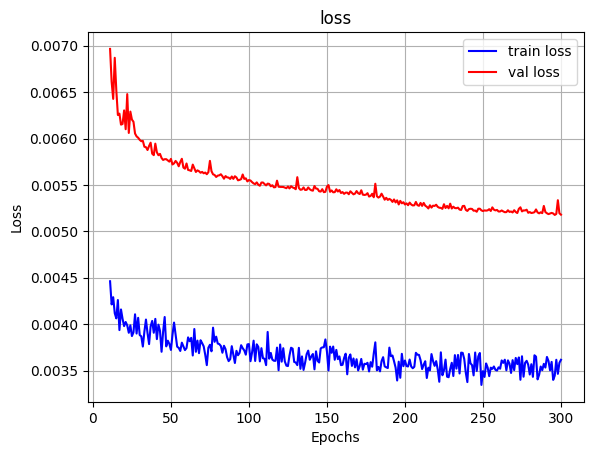

In [3]:
results_folder = '/Users/josephinelahmani/helix_mount/nn_dis/results/train_1'
plot_loss(results_folder, 'total', 10)

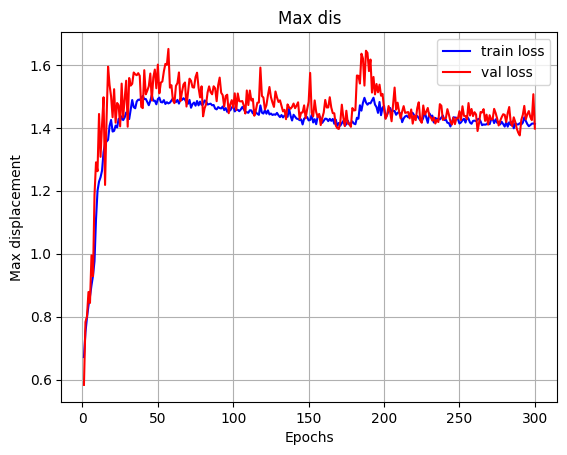

In [4]:
### Plot max dis

train_logs = pd.read_csv(f'{results_folder}/logs_train.csv')
val_logs  = pd.read_csv(f'{results_folder}/logs_validation.csv')
    
epochs = range(1, len(train_logs) + 1)

plt.plot(epochs, train_logs["max_dis"], label='train loss', color='blue')
plt.plot(epochs, val_logs["max_dis"], label='val loss', color='red')
plt.title('Max dis')
plt.xlabel('Epochs')
plt.ylabel('Max displacement')
plt.legend()
plt.grid(True)
plt.show()

Average difference original image 0.03667312
Average difference warped image 0.024980254


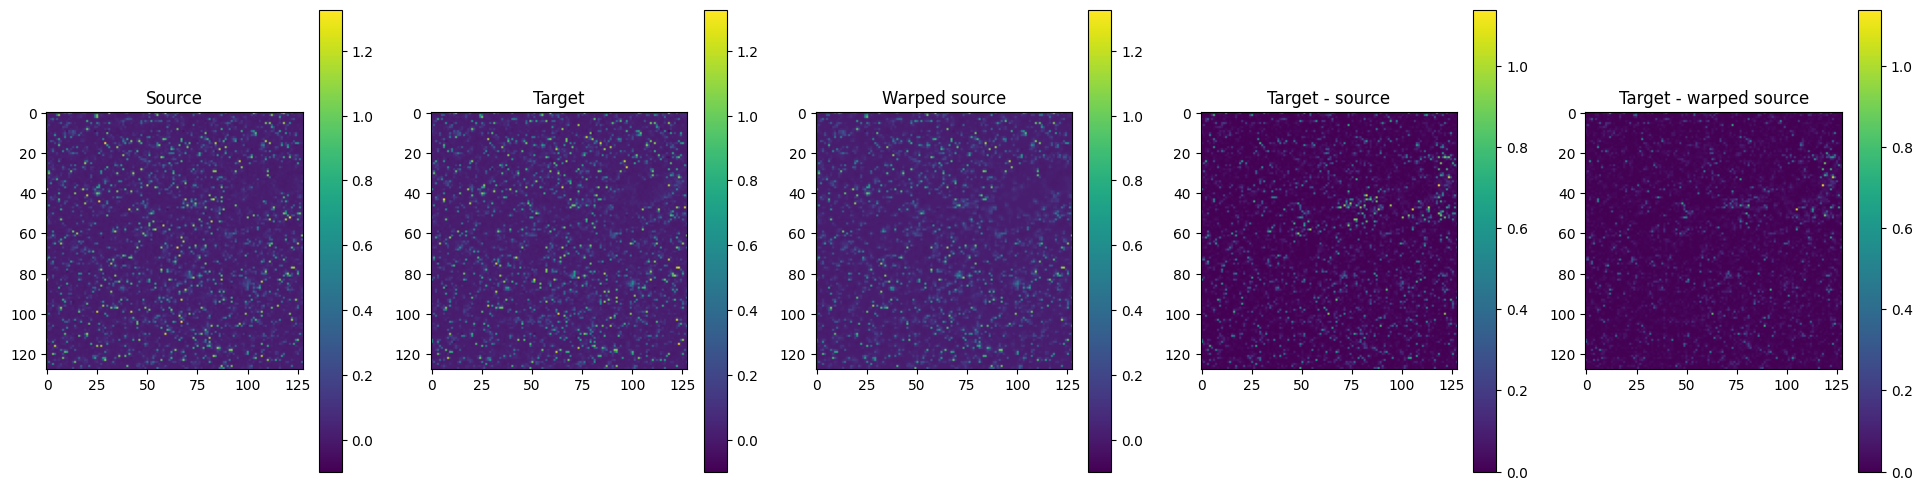

In [ ]:
### Visualize warping results

model_aniso = load_model(results_folder, 'aniso')
#path_img = Path('/Users/josephinelahmani/helix_mount/data/micro/val/250218_WT_1p5CD100RGD_FastAcq_pos2_t0011_t0016.tiff') 
path_img = Path('/Users/josephinelahmani/helix_mount/data/micro/test/250219_WT_1p5CD100RGD_FastAcq_pos3_t0039_t0042.tiff') 

img_padded, displacement, warped_source = get_img_and_results(path_img, model_aniso)
mask_2d = compute_mask(img_padded)
im_vxm = warped_source.detach().numpy()[0,0]

z_stack = 15

check_vxm(img_padded, im_vxm, z_stack = z_stack)

Min: -1.1074
Max: 1.0869
Mean abs: 0.1194


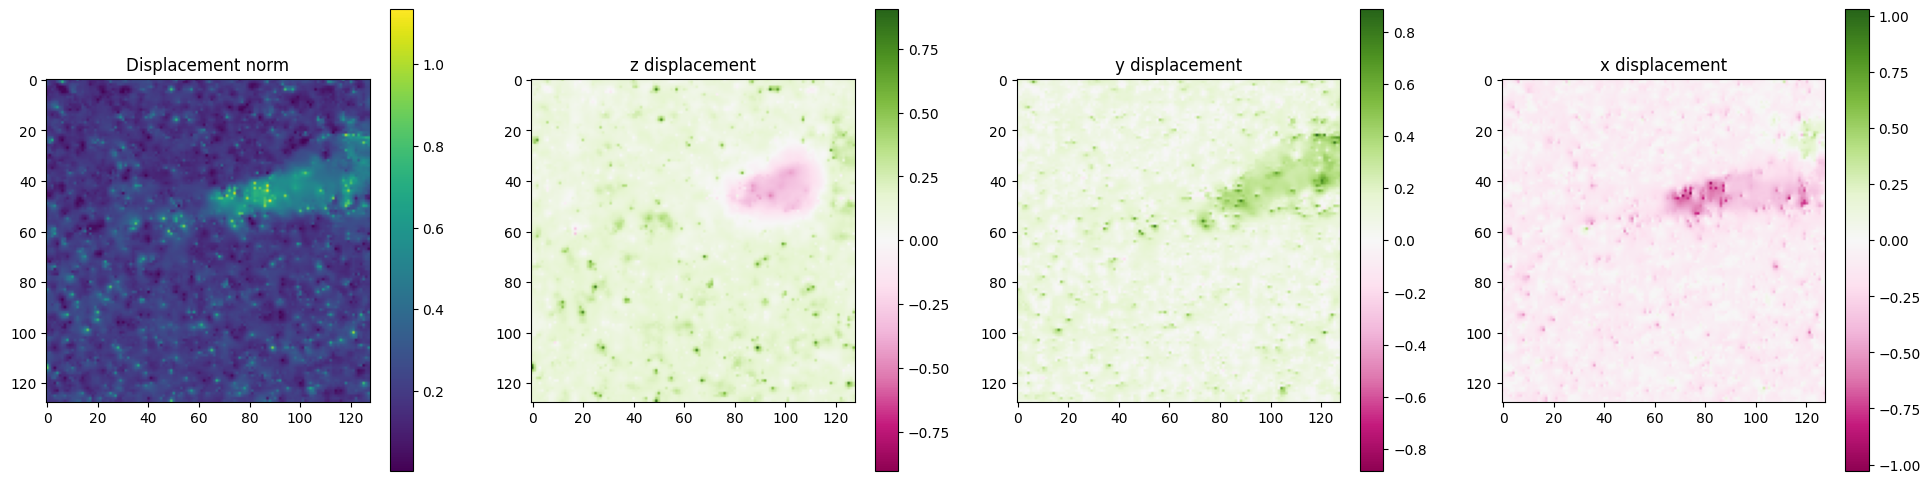

In [14]:
### Visualize displacement results

dis = displacement.detach().numpy()

print(f"Min: {displacement.min():.4f}")
print(f"Max: {displacement.max():.4f}")
print(f"Mean abs: {displacement.abs().mean():.4f}")

dis_z_max = np.max(np.abs(dis[0, 0, z_stack]))
dis_y_max = np.max(np.abs(dis[0, 1, z_stack]))
dis_x_max = np.max(np.abs(dis[0, 2, z_stack]))

fig, axes = plt.subplots(1, 4, figsize=(24, 6))

im0 = axes[0].imshow(np.linalg.norm(dis[0, :, z_stack], axis=0))
fig.colorbar(im0, ax = axes[0])
axes[0].set_title('Displacement norm')
im1 = axes[1].imshow(dis[0, 0, z_stack], cmap = 'PiYG', vmin = -dis_z_max, vmax = dis_z_max)
fig.colorbar(im1, ax = axes[1])
axes[1].set_title('z displacement')
im2 = axes[2].imshow(dis[0, 1, z_stack], cmap = 'PiYG', vmin = -dis_y_max, vmax = dis_y_max)
fig.colorbar(im2, ax = axes[2])
axes[2].set_title('y displacement')
im3 = axes[3].imshow(dis[0, 2, z_stack], cmap = 'PiYG', vmin = -dis_x_max, vmax = dis_x_max)
fig.colorbar(im3, ax = axes[3])
axes[3].set_title('x displacement')
plt.show()

# Model comparisons

In [ ]:
def save_flow_vxm(folder, model, save_path, name):
    save_path.mkdir(exist_ok=True)
    for path_img in folder.iterdir():
        img_padded, displacement, _ = get_img_and_results(path_img, model)
        
        mask_padded = img_padded[0] > 0.1
        dis_vxm = displacement.detach().numpy()
        dis_vxm_final = np.stack([dis_vxm[:,i] * mask_padded for i in range(dis_vxm.shape[1])])
        np.save(save_path / f"flow_vxm_{path_img.name}_{name}", dis_vxm_final)


def compute_rmse_vxm_all(computed_flows_dir, gt_flow_dir, vxm_versions):
    rmse_summary = []
    
    if isinstance(vxm_versions, dict):
        vxm_versions = list(vxm_versions.values())
    
    all_vxm_files = list(computed_flows_dir.glob("flow_vxm_*.npy"))
    
    img_base_names = set()
    for f in all_vxm_files:
        fname = f.name
        for v in vxm_versions:
            tag = f"_{v}.npy"
            if fname.endswith(tag):
                img_base = fname.replace('flow_vxm_', '').replace(tag, '')
                img_base_names.add(img_base)
                break
    
    for base_name in sorted(img_base_names):
        ugt_name = base_name.replace('_img.npy', '_ugt.npy')
        ugt_path = gt_flow_dir / ugt_name
        
        dis_gt_init = np.load(ugt_path)
        dis_gt = np.stack([
            reshape_img(dis_gt_init[0, 0], 32),
            reshape_img(dis_gt_init[1, 0], 32),
            reshape_img(dis_gt_init[2, 0], 32)
        ])
        
        flow_rmse_results = {"img_name": base_name}
        
        for v in vxm_versions:
            vxm_path = computed_flows_dir / f"flow_vxm_{base_name}_{v}.npy"
            if vxm_path.exists():
                dis_vxm = np.load(vxm_path)
                flow_rmse_results[f"rmse_vxm_{v}"] = float(rmse(dis_vxm[:, 0], dis_gt))
            else:
                flow_rmse_results[f"rmse_vxm_{v}"] = None
                print(f"Warning: {vxm_path} not found.")
        
        rmse_summary.append(flow_rmse_results)
    
    return rmse_summary

In [95]:
models_to_compare = {
    'train_3_mask_new_data': 'a_b_0.0001',
    'train_4': 'a_b_0.01',
    'train_5': 'a_b_0.1', 
    'train_6': 'a_0.1_b_0.01',
    'train_3': 'a_b_0.2', 
    'train_1': 'a_0.1_b_0.5'
}

base_img_folder = Path('/Users/josephinelahmani/helix_mount/data/synthetic/test')
base_results_folder = Path('/Users/josephinelahmani/helix_mount/nn_dis/results')
save_path = Path('/Users/josephinelahmani/helix_mount/data/synthetic/computed_vxm_flows')

for model_folder, name in models_to_compare.items():
    folder = base_results_folder / model_folder
    model = load_model(folder, 'aniso')
    save_flow_vxm(base_img_folder, model, save_path, name)

In [96]:
computed_flows_dir = Path('/Users/josephinelahmani/helix_mount/data/synthetic/computed_vxm_flows')
gt_flow_dir = Path('/Users/josephinelahmani/helix_mount/data/synthetic/all_data')

rmse_results = compute_rmse_vxm_all(computed_flows_dir, gt_flow_dir, models_to_compare)

methods = list(models_to_compare.values())

avg = {}
for m in methods:
    key = f"rmse_vxm_{m}"
    values = [d[key] for d in rmse_results if d.get(key) is not None]
    avg[m] = float(np.mean(values))
    
for method, value in avg.items():
    print(f"{method} : {value}")

a_b_0.0001 : 0.18225780729618338
a_b_0.01 : 0.15448080624143282
a_b_0.1 : 0.1317871119827032
a_0.1_b_0.01 : 0.135420186445117
a_b_0.2 : 0.12823334832986197
a_0.1_b_0.5 : 0.1395939654774136


# Method comparison

In [68]:
def compute_rmse_all_methods(computed_flows_dir, gt_flow_dir):
    rmse_summary = []
    single_computed_flow_files = list(computed_flows_dir.glob("flow_vxm_*.npy"))
    
    for cf_path in single_computed_flow_files:
        cf_name = cf_path.name

        base_name = cf_name.replace('flow_vxm_', '')

        ugt_name = base_name.replace('_img.npy', '_ugt.npy')

        ugt_path = gt_flow_dir / ugt_name
        dis_gt_init = np.load(ugt_path)
        dis_gt = np.stack([reshape_img(dis_gt_init[0, 0], 32), reshape_img(dis_gt_init[1, 0], 32), reshape_img(dis_gt_init[2, 0], 32)])
        dis_fista = np.load(computed_flows_dir / f"flow_fista_{base_name}")
        dis_hs = np.load(computed_flows_dir / f"flow_hs_{base_name}")
        dis_tvl1 = np.load(computed_flows_dir / f"flow_tvl1_{base_name}")
        dis_vxm = np.load(computed_flows_dir / f"flow_vxm_{base_name}")
        
        rmse_fista = rmse(dis_fista[:,0], dis_gt)
        rmse_hs = rmse(dis_hs[:,0], dis_gt)
        rmse_tvl1 = rmse(dis_tvl1[:,0], dis_gt)
        rmse_vxm = rmse(dis_vxm[:,0], dis_gt)

        rmse_summary.append({
            "img_name": cf_name,
            "rmse_fista": float(rmse_fista),
            "rmse_hs": float(rmse_hs),
            "rmse_tvl1": float(rmse_tvl1),
            "rmse_vxm": float(rmse_vxm),
        })
    
    return rmse_summary

def compute_lame(E, nu):
    """
    Computes the Lamé parameters (μ and λ) from Young’s modulus and Poisson’s ratio.

    Args:
        E (float):
            Young’s modulus of the material.
        nu (float):
            Poisson’s ratio of the material.

    Returns:
        tuple[float, float]:
            - `mu_e` (float): Shear modulus (μ).
            - `lambda_e` (float): First Lamé parameter (λ).
    """
    lambda_e = E * nu / ((1.0 + nu) * (1.0 - 2.0 * nu))
    mu_e = E / (2.0 * (1.0 + nu))
    return mu_e, lambda_e


def compute_mec_stuff(name, computed_flows_dir, gt_flow_dir, mask, normals):

    ugt_name = name.replace('_img.npy', '_ugt.npy')

    ugt_path = gt_flow_dir / ugt_name
    
    matchE = re.search(r"E_(\d+)", name)
    if matchE is not None:
        E = float(matchE.group(1))
        
    matchnu = re.search(r"_nu_(\d+)", name)
    if matchnu is not None:
        nu = float(matchnu.group(1))
    
    mu, lambda_ = compute_lame(E, nu)
    
    displacements = {
        "gt":    np.load(ugt_path),
        "fista": np.load(computed_flows_dir / f"flow_fista_{name}"),
        "hs":    np.load(computed_flows_dir / f"flow_hs_{name}"),
        "tvl1":  np.load(computed_flows_dir / f"flow_tvl1_{name}"),
        "vxm":   np.load(computed_flows_dir / f"flow_vxm_{name}")
    }
    
    results = {}
    dis_gt_init = displacements["gt"]
    dis_gt = np.stack([reshape_img(dis_gt_init[0, 0], 32), reshape_img(dis_gt_init[1, 0], 32), reshape_img(dis_gt_init[2, 0], 32)])
    dis_gt = np.expand_dims(dis_gt, axis=1)
    strain_gt = strain_mask(dis_gt, [1, 1, 1], mask)
    def_grad_gt = deformation(strain_gt)
    stress_gt = stress_mask(strain_gt, mu, lambda_)
    traction_gt = compute_traction_3d(stress_gt[:,:,0], -normals)

    results["gt"] = {
        "displacement": dis_gt,        
        "deformation":  def_grad_gt,
        "strain":       strain_gt,
        "stress":       stress_gt,
        "normals":      normals,
        "traction":     traction_gt,
    }

    methods = ["fista", "hs", "tvl1", "vxm"]
    
    for method in methods:
        dis = displacements[method]
        
        strain = strain_mask(dis, [1, 1, 1], mask)
        def_grad = deformation(strain)
        stress = stress_mask(strain, mu, lambda_)
        traction = compute_traction_3d(stress[:,:,0], -normals)

        results[method] = {
            "displacement": dis,        
            "deformation":  def_grad,
            "strain":       strain,
            "stress":       stress,
            "normals":      normals,
            "traction":     traction,
            
            "rmse_displacement": rmse(dis, dis_gt),
            "rmse_deformation":  rmse(def_grad, def_grad_gt),
            "rmse_strain":       rmse(strain, strain_gt),
            "rmse_stress":       rmse(stress, stress_gt),
            "rmse_traction":     rmse(traction, traction_gt),
        }

    return results

In [ ]:
folder = Path('/Users/josephinelahmani/helix_mount/data/synthetic/test')

save_path = Path('/Users/josephinelahmani/helix_mount/data/synthetic/computed_flows')
save_path.mkdir(exist_ok=True)

save_flow_vxm(folder, model_aniso, save_path)

In [ ]:
computed_flows_dir = Path('/Users/josephinelahmani/helix_mount/data/synthetic/computed_flows')
gt_flow_dir = Path('/Users/josephinelahmani/helix_mount/data/synthetic/all_data')

rmse_summary = compute_rmse_all_methods(computed_flows_dir, gt_flow_dir)

methods = ['rmse_fista', 'rmse_hs', 'rmse_tvl1', 'rmse_vxm']

avg = {m: np.mean([d[m] for d in rmse_summary]) for m in methods}

for method, value in avg.items():
    print(f"{method} : {value}")

In [ ]:

img_name = 'E_500.0_nu_0.4_nb_zones_9_im_00_seed_08_img.npy' #'E_1000.0_nu_0.4_nb_zones_9_im_01_seed_01_img.npy'
folder = Path('/Users/josephinelahmani/helix_mount/data/synthetic/test')
img_raw = np.load(folder / f"{img_name}")
q1, q99 = np.quantile(img_raw, [0.01, 0.99])
img = np.clip((img_raw - q1) / (q99 - q1), 0, 1)

img_padded = np.stack([reshape_img(img[0], 32), reshape_img(img[1], 32)], axis=0)

mask = img_padded[0] > 0.1

mask_eroded = ndi.binary_erosion(mask)
inner_boundary_gt = mask_eroded & (~ndi.binary_erosion(mask_eroded))
normals = compute_normals_from_mask_3d(mask_eroded)
normals[:, ~inner_boundary_gt] = 0

results = compute_mec_stuff(img_name, computed_flows_dir, gt_flow_dir, normals) 

In [42]:
metrics = ["displacement", "deformation", "strain", "stress", "traction"]
methods = ["fista", "hs", "tvl1", 'vxm']

for metric in metrics:
    print(f"\n{metric}")
    for method in methods:
        val = results[method][f"rmse_{metric}"]
        print(f"{method:<8} : {val:.6e}")


displacement
fista    : 1.428353e-01
hs       : 1.563871e-01
tvl1     : 1.521091e-01
vxm      : 1.635397e-01

deformation
fista    : 5.114334e-02
hs       : 4.766799e-02
tvl1     : 4.865333e-02
vxm      : 4.872380e-02

strain
fista    : 2.076933e-02
hs       : 2.262412e-02
tvl1     : 2.357346e-02
vxm      : 2.443072e-02

stress
fista    : 2.076933e+01
hs       : 2.262412e+01
tvl1     : 2.357346e+01
vxm      : 2.443072e+01

traction
fista    : 2.124405e+01
hs       : 2.268356e+01
tvl1     : 2.322456e+01
vxm      : 2.411972e+01


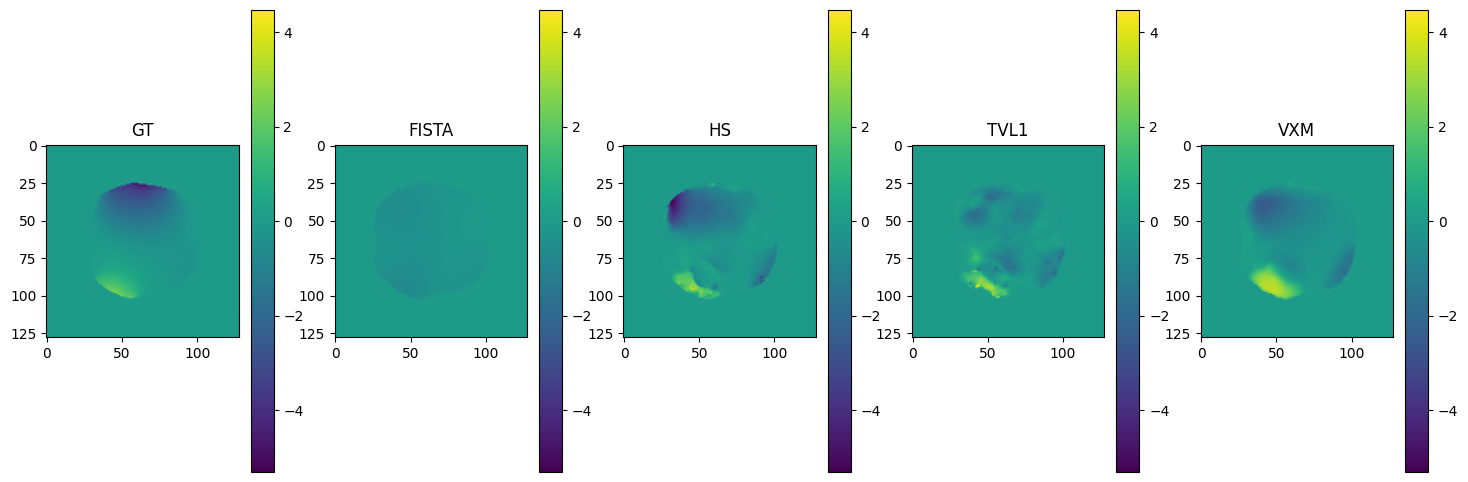

In [50]:
methods = ["gt", "fista", "hs", "tvl1", "vxm"]
method_titles = ["GT", "FISTA", "HS", "TVL1", "VXM"]
frame = 15
ax = 0

fig, axes = plt.subplots(1, len(methods), figsize=(18, 6))

all_values = np.concatenate([results[m]['displacement'][ax, 0, frame, :].ravel() for m in methods])
vmin, vmax = all_values.min(), all_values.max()

for j, m in enumerate(methods):
    im = axes[j].imshow(results[m]['displacement'][ax, 0, frame, :], vmin=vmin, vmax=vmax)
    fig.colorbar(im, ax=axes[j])

    axes[j].set_title(method_titles[j], fontsize=12)

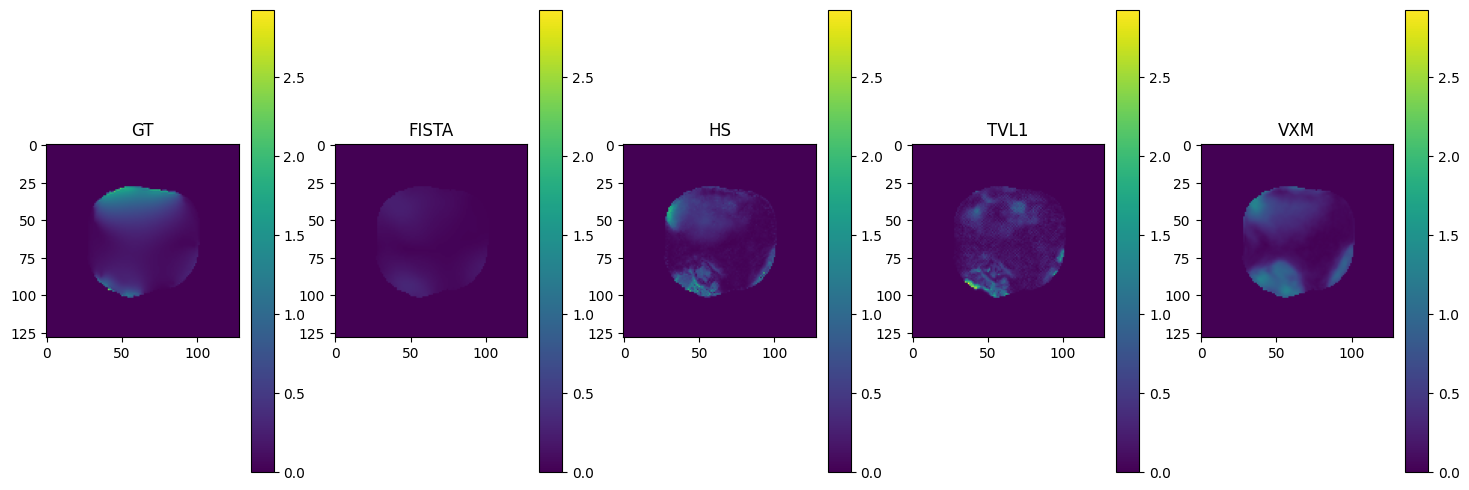

In [51]:
fig, axes = plt.subplots(1, len(methods), figsize=(18, 6))

all_values = np.concatenate([results[m]['deformation'][0, frame, :].ravel() for m in methods])
vmin, vmax = all_values.min(), all_values.max()

for j, m in enumerate(methods):
    im = axes[j].imshow(results[m]['deformation'][0, frame, :], vmin=vmin, vmax=vmax)
    fig.colorbar(im, ax=axes[j])

    axes[j].set_title(method_titles[j], fontsize=12)

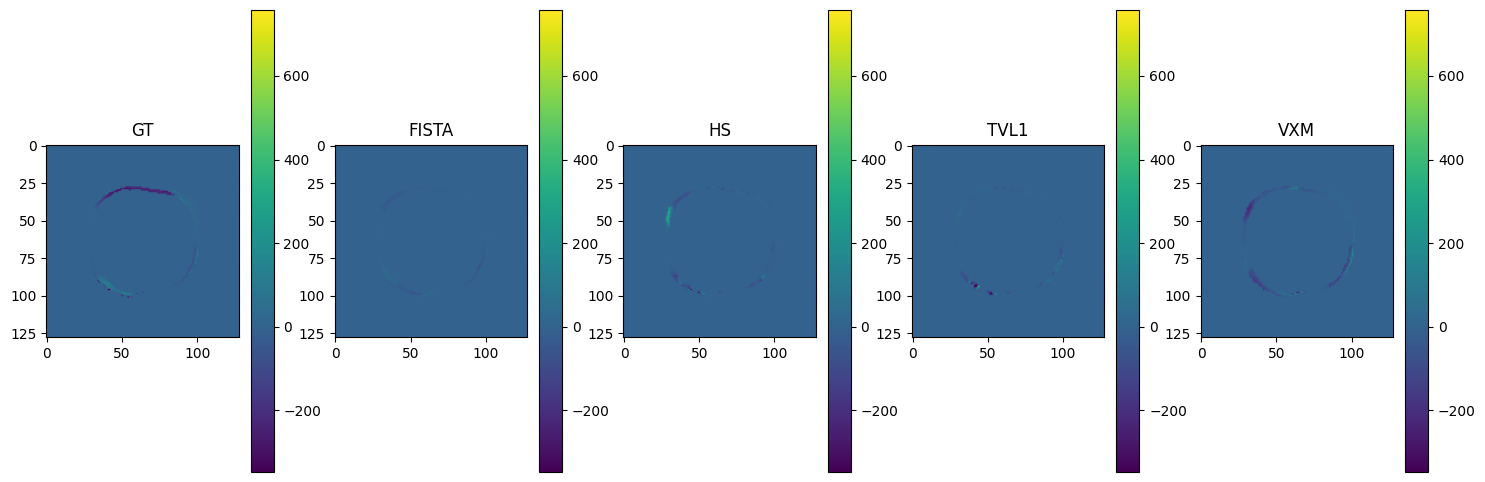

In [52]:
fig, axes = plt.subplots(1, len(methods), figsize=(18, 6))

all_values = np.concatenate([results[m]['traction'][1, frame, :].ravel() for m in methods])
vmin, vmax = all_values.min(), all_values.max()

for j, m in enumerate(methods):
    im = axes[j].imshow(results[m]['traction'][2, frame, :], vmin=vmin, vmax=vmax)
    fig.colorbar(im, ax=axes[j])

    axes[j].set_title(method_titles[j], fontsize=12)